# **Hotel Booking Analysis Assignment**



In [68]:
# Inporting libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
# Load dataset
df = pd.read_csv('/content/sample_data/Hotels Booking Data.csv')


# **STEP 1: Understandiong the Data**

In [70]:
df.shape

(30000, 26)

In [71]:
# Understanding the Data
df.head()

,customer_id,property_id,city,star_rating,booking_date,check_in_date,check_out_date,room_type,num_rooms_booked,stay_type,...,refund_status,refund_amount,channel_of_booking,booking_status,travel_date,cashback,coupon_redeem,Coupon USed?,length_of_stay,is_weekend_checkin
0,492,3,San Francisco,4,2024-04-01,2024-05-24,2024-05-26,Standard,1,Leisure,...,Yes,369.65,Web,Confirmed,2024-03-04,5.37,0.0,No,2.0,True
1,180,3,Dallas,3,2024-04-01,2024-05-10,2024-05-17,Deluxe,1,Leisure,...,Yes,492.51,Web,Confirmed,2024-07-19,7.16,0.0,No,7.0,True
2,50,5,Dallas,3,2024-04-01,2024-05-31,2024-06-05,Deluxe,1,Business,...,Yes,0.00,iOS,Confirmed,2024-03-22,0.00,0.0,No,5.0,True
3,294,3,Orlando,4,2024-04-01,2024-04-18,2024-04-24,Deluxe,3,Leisure,...,Yes,545.54,Android,Confirmed,2024-11-24,7.93,24.5,Yes,6.0,False
4,40,5,Seattle,5,2024-04-01,NaN,NaN,Deluxe,1,Leisure,...,Yes,211.37,Web,Cancelled,2024-03-02,0.00,0.0,No,NaN,False


In [72]:
# Understanding the Null values and DataType
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         30000 non-null  int64  
 1   property_id         30000 non-null  int64  
 2   city                30000 non-null  object 
 3   star_rating         30000 non-null  int64  
 4   booking_date        30000 non-null  object 
 5   check_in_date       24532 non-null  object 
 6   check_out_date      24532 non-null  object 
 7   room_type           30000 non-null  object 
 8   num_rooms_booked    30000 non-null  int64  
 9   stay_type           30000 non-null  object 
 10  booking_channel     30000 non-null  object 
 11  booking_value       30000 non-null  float64
 12  costprice           30000 non-null  int64  
 13  markup              30000 non-null  float64
 14  selling_price       30000 non-null  float64
 15  payment_method      30000 non-null  object 
 16  refu

In [73]:
# Correcting the Column Name as it has ? and spacing
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(' ', '_')
      .str.replace('?', '', regex=False)
)

df.columns


Index(['customer_id', 'property_id', 'city', 'star_rating', 'booking_date',
       'check_in_date', 'check_out_date', 'room_type', 'num_rooms_booked',
       'stay_type', 'booking_channel', 'booking_value', 'costprice', 'markup',
       'selling_price', 'payment_method', 'refund_status', 'refund_amount',
       'channel_of_booking', 'booking_status', 'travel_date', 'cashback',
       'coupon_redeem', 'coupon_used', 'length_of_stay', 'is_weekend_checkin'],
      dtype='object')

**Checking missing data**

In [74]:
df.isna().sum().sort_values(ascending=False)


,0
check_out_date,5468
check_in_date,5468
length_of_stay,5468
property_id,0
star_rating,0
customer_id,0
booking_date,0
room_type,0
num_rooms_booked,0
city,0


**statistical overview**

In [75]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,30000.0,NaN,NaN,NaN,249.721767,145.484836,1.0,123.0,248.0,376.0,499.0
property_id,30000.0,NaN,NaN,NaN,3.777533,2.081471,1.0,1.0,3.0,5.0,7.0
city,30000,10,Chicago,3059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
star_rating,30000.0,NaN,NaN,NaN,3.602033,0.860241,2.0,3.0,4.0,4.0,5.0
booking_date,30000,395,2025-02-24,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
check_in_date,24532,452,2025-04-28,82,NaN,NaN,NaN,NaN,NaN,NaN,NaN
check_out_date,24532,453,2025-01-06,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
room_type,30000,3,Standard,16552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_rooms_booked,30000.0,NaN,NaN,NaN,1.352333,0.574403,1.0,1.0,1.0,2.0,3.0
stay_type,30000,2,Leisure,18110,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Convert date columns**

In [76]:
date_cols = [
    'booking_date',
    'check_in_date',
    'check_out_date',
    'travel_date'
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')


# **STEP 2: Handling missing values**

In [77]:
# Drop rows where booking status is missing (critical)
df = df.dropna(subset=['booking_status'])

# Fill length_of_stay using dates where possible
df['length_of_stay'] = (
    df['check_out_date'] - df['check_in_date']
).dt.days

# Fill remaining missing stay lengths with median
df['length_of_stay'].fillna(df['length_of_stay'].median(), inplace=True)


/tmp/ipython-input-706190770.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['length_of_stay'].fillna(df['length_of_stay'].median(), inplace=True)


converting values to lowercase to avoid inconsistencies caused by variations in text formatting

In [78]:
df['booking_status'] = df['booking_status'].str.lower()
df['channel_of_booking'] = df['channel_of_booking'].str.lower()
df['room_type'] = df['room_type'].str.lower()
df['stay_type'] = df['stay_type'].str.lower()


# **STEP 3: Feature Engineering**

In [79]:
# Finfing overall booking status
df['booking_status'].value_counts(normalize=True) * 100


,proportion
booking_status,
confirmed,73.210000
cancelled,19.263333
failed,7.526667


**Bookings by channel**

In [80]:
df['channel_of_booking'].value_counts()


,count
channel_of_booking,
web,16023
android,9505
ios,4472


**Bookings by star rating**

In [81]:
df['star_rating'].value_counts().sort_index()


,count
star_rating,
2,2995
3,10460
4,12034
5,4511


**Average booking value by channel**

In [82]:
df.groupby('channel_of_booking')['booking_value'].mean().sort_values(ascending=False)



,booking_value
channel_of_booking,
android,25355.242358
web,24973.016853
ios,24881.828258


**Cancellation rate by channel**

In [83]:
df.groupby('channel_of_booking')['booking_status'] \
  .apply(lambda x: (x == 'cancelled').mean() * 100) \
  .sort_values(ascending=False)


,booking_status
channel_of_booking,
ios,20.192308
android,19.410836
web,18.916557


# **STEP 4: EDA Visualizations**

**Booking Status**

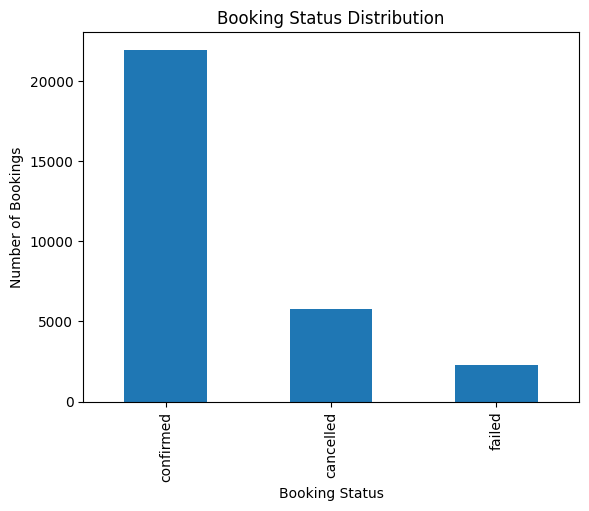

In [84]:
# Booking Status
plt.figure()
df['booking_status'].value_counts().plot(kind='bar')
plt.title('Booking Status Distribution')
plt.xlabel('Booking Status')
plt.ylabel('Number of Bookings')
plt.show()


A significant portion of bookings result in cancellations

**Bookings by Channel**

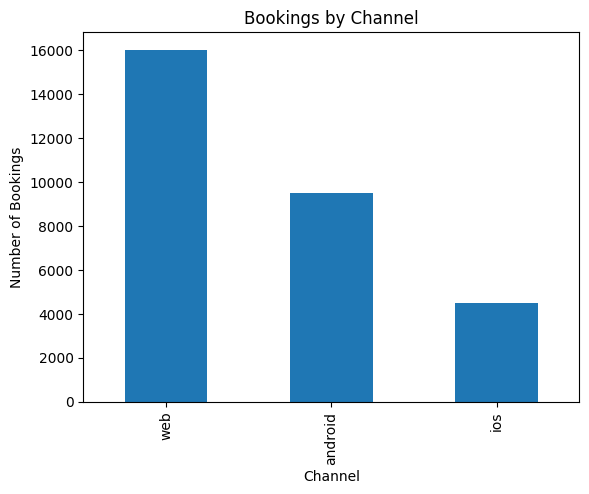

In [85]:
plt.figure()
df['channel_of_booking'].value_counts().plot(kind='bar')
plt.title('Bookings by Channel')
plt.xlabel('Channel')
plt.ylabel('Number of Bookings')
plt.show()


Most of the boking are made through androide. it means that the web and ios contribute disproportionately to total booking volume.

**Average Booking Value by Star Rating**

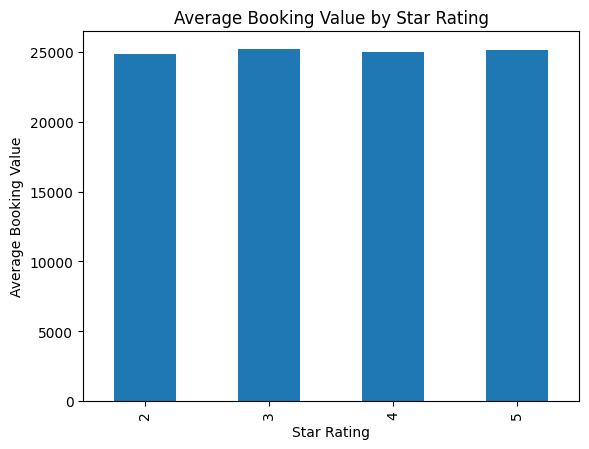

In [86]:
plt.figure()
df.groupby('star_rating')['booking_value'].mean().plot(kind='bar')
plt.title('Average Booking Value by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Average Booking Value')
plt.show()



Average booking is almose same in comparison to the variouse star rated hotels


**Cancellation Rate by Channel**

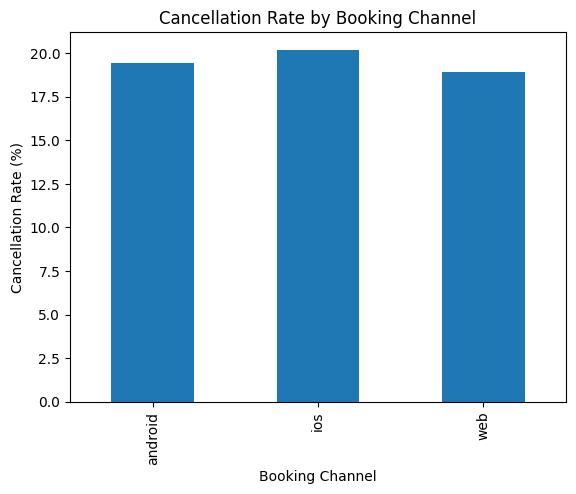

In [87]:
cancel_rate_channel = (
    df.groupby('channel_of_booking')['booking_status']
      .apply(lambda x: (x == 'cancelled').mean() * 100)
)

plt.figure()
cancel_rate_channel.plot(kind='bar')
plt.title('Cancellation Rate by Booking Channel')
plt.xlabel('Booking Channel')
plt.ylabel('Cancellation Rate (%)')
plt.show()


Cancellation rate is simmilar in various channels. indicating the channel has nothing to do with the cancellation

**Room Type vs Cancellation Rate**

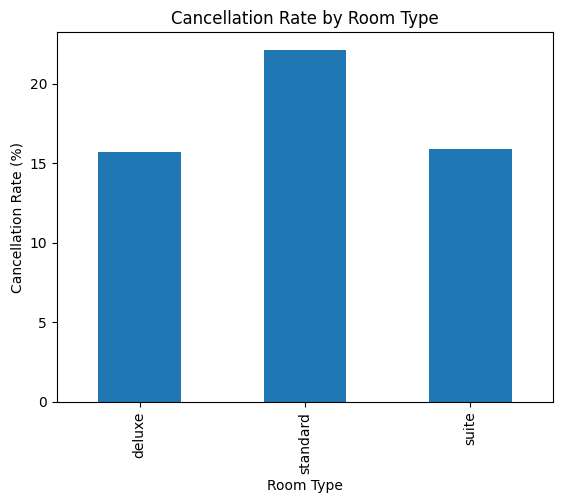

In [88]:
cancel_rate_room = (
    df.groupby('room_type')['booking_status']
      .apply(lambda x: (x == 'cancelled').mean() * 100)
)

plt.figure()
cancel_rate_room.plot(kind='bar')
plt.title('Cancellation Rate by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Cancellation Rate (%)')
plt.show()


Here we can see the significant amout of cancellation among the diffferent room type. where the standard rooms are cancelled more. it can be becouse og the services , pricing,food etc.


# **STEP 5: Root Cause Analysis for  Cancellations**

**Overall Cancellation Rate**

In [89]:
overall_cancel_rate = (df['booking_status'] == 'cancelled').mean() * 100
overall_cancel_rate


np.float64(19.263333333333332)

Overall cancel rate is 19


**Cancellation Rate by Booking Channel**

In [90]:
df.groupby('channel_of_booking')['booking_status'] \
  .apply(lambda x: (x == 'cancelled').mean() * 100) \
  .sort_values(ascending=False)


,booking_status
channel_of_booking,
ios,20.192308
android,19.410836
web,18.916557


The cancellation rate is more with ios. Its maybe becouse the channel allows easy cancellation or has weak intent.

**Cancellation vs Lead Time**

In [91]:
df['lead_time'] = (df['check_in_date'] - df['booking_date']).dt.days

lead_time_cancel = df.groupby(pd.cut(df['lead_time'], bins=[0,7,14,30,60,120,365]))['booking_status'] \
    .apply(lambda x: (x == 'cancelled').mean() * 100)

lead_time_cancel


/tmp/ipython-input-4085330866.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lead_time_cancel = df.groupby(pd.cut(df['lead_time'], bins=[0,7,14,30,60,120,365]))['booking_status'] \


,booking_status
lead_time,
"(0, 7]",3.902773
"(7, 14]",4.556355
"(14, 30]",4.454377
"(30, 60]",4.351032
"(60, 120]",NaN
"(120, 365]",NaN


Longer lead times increase uncertainty which results in higher cancellation probability

# **STEP 6: Root-Cause Visualizations**

**Cancellation Rate by Lead Time**

/tmp/ipython-input-4149548882.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('lead_time_bucket')['booking_status']


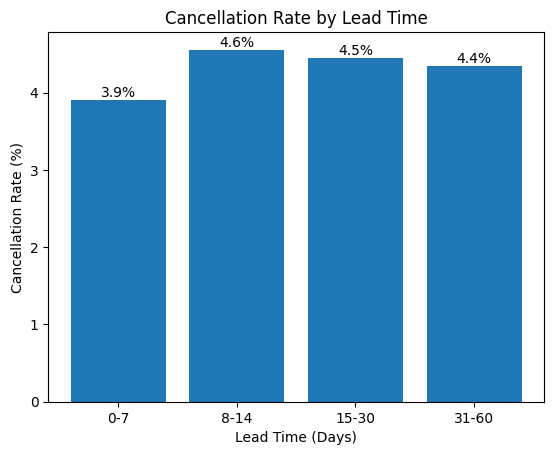

In [97]:
# Creating  lead time buckets
df['lead_time_bucket'] = pd.cut(
    df['lead_time'],
    bins=[0, 7, 14, 30, 60, 120, 365],
    labels=['0-7', '8-14', '15-30', '31-60', '61-120', '120+']
)

lead_time_cancel = (
    df.groupby('lead_time_bucket')['booking_status']
      .apply(lambda x: (x == 'cancelled').mean() * 100)
)

fig, ax = plt.subplots()
ax.bar(lead_time_cancel.index, lead_time_cancel.values)

add_bar_labels(ax, lead_time_cancel.values, is_percent=True)

ax.set_title('Cancellation Rate by Lead Time')
ax.set_xlabel('Lead Time (Days)')
ax.set_ylabel('Cancellation Rate (%)')
plt.show()


Cancellation likelihood increases with longer lead times due to higher uncertainty in travel plans. most cancellation has accure in the 8,14th days og the booking

**Cancellation vs Coupon Usage**

In [92]:
df.groupby('coupon_used')['booking_status'] \
  .apply(lambda x: (x == 'cancelled').mean() * 100)


,booking_status
coupon_used,
No,18.801193
Yes,21.039884


Coupon users tend to be:
More deal-driven, Less loyal, More likely to abandon bookings

**Cancellation vs Star Rating**

In [93]:
def add_bar_labels(ax, values, is_percent=False):
    for i, v in enumerate(values):
        label = f"{v:.1f}%" if is_percent else f"{int(v)}"
        ax.text(i, v, label, ha='center', va='bottom')

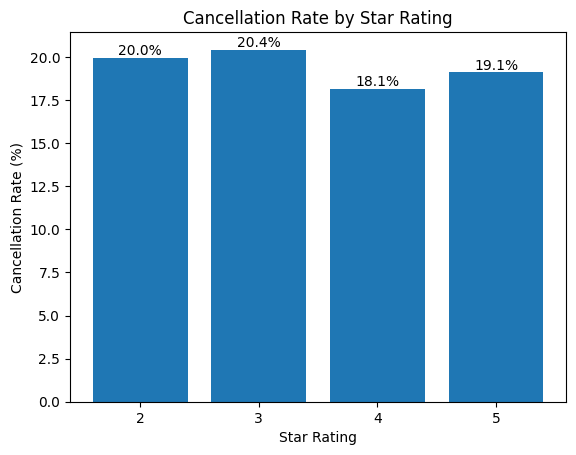

In [94]:
star_cancel = (
    df.groupby('star_rating')['booking_status']
      .apply(lambda x: (x == 'cancelled').mean() * 100)
)

fig, ax = plt.subplots()
ax.bar(star_cancel.index.astype(str), star_cancel.values)

add_bar_labels(ax, star_cancel.values, is_percent=True)

ax.set_title('Cancellation Rate by Star Rating')
ax.set_xlabel('Star Rating')
ax.set_ylabel('Cancellation Rate (%)')
plt.show()


Hotels with low rating of 3 has been cancelled more. it can be becouse of the Lower perceived quality, Price competition,Expectation mismatch

**Cancellation vs Room Type**

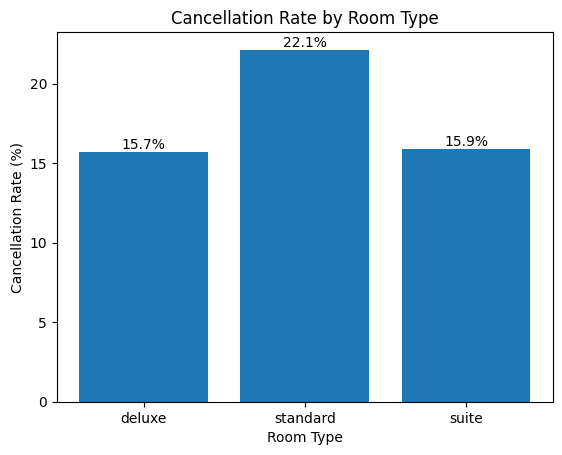

In [95]:
room_cancel = (
    df.groupby('room_type')['booking_status']
      .apply(lambda x: (x == 'cancelled').mean() * 100)
)

fig, ax = plt.subplots()
ax.bar(room_cancel.index, room_cancel.values)

add_bar_labels(ax, room_cancel.values, is_percent=True)

ax.set_title('Cancellation Rate by Room Type')
ax.set_xlabel('Room Type')
ax.set_ylabel('Cancellation Rate (%)')
plt.show()


Room type shows that the standard rooms are cancelled more. suggesting price sensitivity or availability concern.

**Channel vs Cancellation Rate**

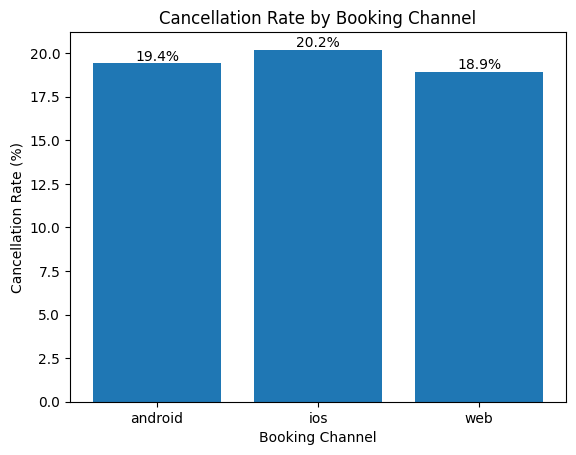

In [96]:
channel_cancel = (
    df.groupby('channel_of_booking')['booking_status']
      .apply(lambda x: (x == 'cancelled').mean() * 100)
)

fig, ax = plt.subplots()
ax.bar(channel_cancel.index, channel_cancel.values)

add_bar_labels(ax, channel_cancel.values, is_percent=True)

ax.set_title('Cancellation Rate by Booking Channel')
ax.set_xlabel('Booking Channel')
ax.set_ylabel('Cancellation Rate (%)')
plt.show()


Cancellations are more in the ios channels. Its maybe becouse the channel allows easy cancellation or has weak intent.



# **STEP 7: Seasonal / Temporal Analysis**

**Monthly booking trend**

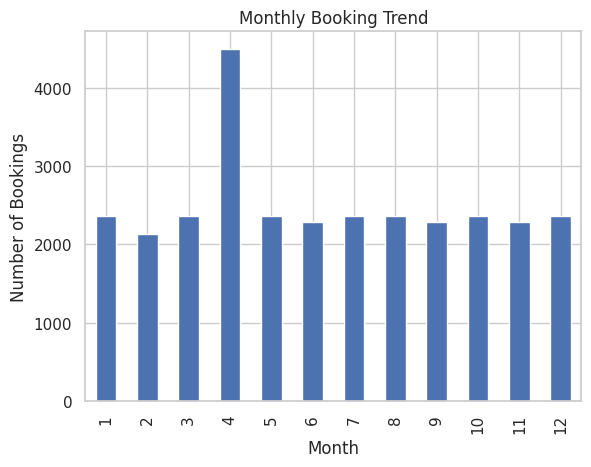

In [106]:
df['booking_month'] = df['booking_date'].dt.month

monthly_bookings = df.groupby('booking_month').size()

plt.figure()
monthly_bookings.plot(kind='bar')
plt.title('Monthly Booking Trend')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.show()


Booking volumes vary across months, indicating seasonality in travel demand.

**Monthly cancellation rate**

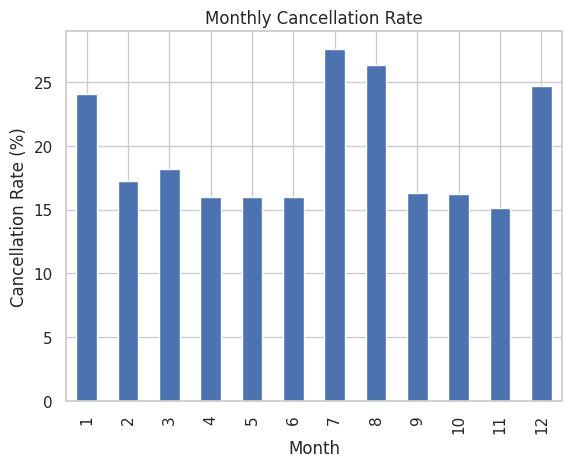

In [107]:
monthly_cancel = (
    df.groupby('booking_month')['booking_status']
      .apply(lambda x: (x == 'cancelled').mean() * 100)
)

plt.figure()
monthly_cancel.plot(kind='bar')
plt.title('Monthly Cancellation Rate')
plt.xlabel('Month')
plt.ylabel('Cancellation Rate (%)')
plt.show()


Certain months like 1,7,8,12th show higher cancellation rates, likely due to weather uncertainty, holiday planning changes, or flexible travel intent.